[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SEU_USUARIO/SEU_REPOSITORIO/blob/main/Aula_Econometria.ipynb)

<!-- 
INSTRUÇÕES (apague este comentário depois de configurar):
1. Troque SEU_USUARIO pelo seu nome de usuário do GitHub
2. Troque SEU_REPOSITORIO pelo nome do repositório
3. Se o arquivo tiver outro nome ou a branch não for 'main', ajuste também

Exemplo final:
https://colab.research.google.com/github/francis/econometria-iv-aula/blob/main/Aula_Econometria.ipynb
-->

# AULA DE ECONOMETRIA: OLS, IV e 2SLS
## Análise Visual com Simulações de Monte Carlo

### Objetivos:
1. Demonstrar que OLS é **consistente** quando as hipóteses do PGD são satisfeitas
2. Mostrar que OLS é **viesado** quando há variáveis omitidas correlacionadas com regressores
3. Explorar soluções: **proxy** e **instrumental variables (IV)**
4. Ilustrar o papel da **força do instrumento** vs **proxy fraco**

## 0. INSTALAÇÃO DE DEPENDÊNCIAS (Colab)

In [1]:
# Instalar linearmodels se não estiver disponível (para Colab)
import sys
import subprocess

try:
    import linearmodels
    print("✓ linearmodels já está instalado")
except ImportError:
    print("Instalando linearmodels...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "linearmodels", "-q"])
    print("✓ linearmodels instalado com sucesso!")

✓ linearmodels já está instalado


## 1. IMPORTS E CONFIGURAÇÃO

In [2]:
# Importações necessárias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.regression.linear_model import OLS
from statsmodels.tools.tools import add_constant
from linearmodels.iv import IV2SLS  # ← Usando linearmodels (mais moderno!)
import warnings
warnings.filterwarnings('ignore')

# Configurar estilo visual
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("✓ Imports realizado com sucesso!")
print("\nEstamos prontos para começar a aula.")

✓ Imports realizado com sucesso!

Estamos prontos para começar a aula.


## 2. MODELO E PROCESSO GERADOR DE DADOS (PGD)

### Modelo Teórico

$$y = \beta_1 + \beta_2 x + \beta_3 h + v$$

Onde:
- $\beta_1 = 2.0$ (intercepto verdadeiro)
- $\beta_2 = 1.5$ (efeito de x)
- $\beta_3 = 0.8$ (efeito de h)
- $x \sim N(0,1)$ **[exógeno]**
- $h = 0.6x + u$, onde $u \sim N(0, 0.64)$ **[endógeno: correlacionado com x]**
- $v \sim N(0, 0.5^2)$ **[ruído idiossincrático]**

In [3]:
# =====================================================
# PARÂMETROS VERDADEIROS DO MODELO
# =====================================================

b1_true = 2.0    # intercepto
b2_true = 1.5    # coeficiente de x (exógeno)
b3_true = 0.8    # coeficiente de h (endógeno, será omitido)

print("="*70)
print("PARÂMETROS DO MODELO VERDADEIRO")
print("="*70)
print(f"\ny = {b1_true} + {b2_true}*x + {b3_true}*h + v")
print(f"\nβ₁ (intercepto) = {b1_true}")
print(f"β₂ (coef. de x) = {b2_true}")
print(f"β₃ (coef. de h) = {b3_true}")
print(f"\nViés teórico quando omitimos h:")
print(f"  Viés = β₃ × Corr(x,h) = {b3_true} × 0.6 = {b3_true * 0.6:.4f}")

PARÂMETROS DO MODELO VERDADEIRO

y = 2.0 + 1.5*x + 0.8*h + v

β₁ (intercepto) = 2.0
β₂ (coef. de x) = 1.5
β₃ (coef. de h) = 0.8

Viés teórico quando omitimos h:
  Viés = β₃ × Corr(x,h) = 0.8 × 0.6 = 0.4800


## 3. FUNÇÃO GERADORA DE DADOS (PGD)

In [4]:
def gerar_dados(n, seed=None):
    """
    Gera uma amostra do Processo Gerador de Dados (PGD).
    
    Retorna:
    - y: variável dependente (n,)
    - x: variável exógena (n,)
    - h: variável endógena correlacionada com x (n,)
    - v: termo de erro (n,)
    """
    if seed is not None:
        np.random.seed(seed)
    
    # 1. Gerar x exógeno
    x = np.random.normal(0, 1, n)
    
    # 2. Gerar h endógeno: h = 0.6*x + u
    u = np.random.normal(0, np.sqrt(1 - 0.6**2), n)
    h = 0.6 * x + u
    
    # 3. Gerar ruído idiossincrático
    v = np.random.normal(0, 0.5, n)
    
    # 4. Calcular y
    y = b1_true + b2_true * x + b3_true * h + v
    
    return y, x, h, v

# Teste: gerar uma amostra pequena
y_test, x_test, h_test, v_test = gerar_dados(n=100, seed=123)

print("✓ Função geradora de dados criada com sucesso!")
print(f"\nTeste com n=100:")
print(f"  Correlação(x, h) = {np.corrcoef(x_test, h_test)[0,1]:.4f}")
print(f"  Média de y = {y_test.mean():.4f}")
print(f"  Desvio de y = {y_test.std():.4f}")

✓ Função geradora de dados criada com sucesso!

Teste com n=100:
  Correlação(x, h) = 0.6490
  Média de y = 1.9936
  Desvio de y = 2.3326


## 4. PARÂMETROS DAS SIMULAÇÕES

In [5]:
# =====================================================
# CONFIGURAÇÃO DAS SIMULAÇÕES DE MONTE CARLO
# =====================================================

n_replicas = 500      # número de réplicas
n_amostra = 300       # tamanho da amostra em cada réplica

# Força do proxy e instrumento (ajustáveis)
forca_proxy = 0.7                    # Corr(proxy, h)
forca_instrumento_forte = 0.80       # Corr(z_forte, h)
forca_instrumento_fraco = 0.25       # Corr(z_fraco, h)

print("="*70)
print("CONFIGURAÇÃO DAS SIMULAÇÕES")
print("="*70)
print(f"\nNúmero de réplicas de Monte Carlo: {n_replicas}")
print(f"Tamanho da amostra em cada réplica: {n_amostra}")
print(f"\nForça do proxy: {forca_proxy}")
print(f"Força do instrumento (forte): {forca_instrumento_forte}")
print(f"Força do instrumento (fraco): {forca_instrumento_fraco}")

CONFIGURAÇÃO DAS SIMULAÇÕES

Número de réplicas de Monte Carlo: 500
Tamanho da amostra em cada réplica: 300

Força do proxy: 0.7
Força do instrumento (forte): 0.8
Força do instrumento (fraco): 0.25


## 5. SIMULAÇÃO 1: OLS COM ESPECIFICAÇÃO CORRETA

### Cenário:
Observamos **x e h** (ambas variáveis). Estimamos:
$$y = \beta_1 + \beta_2 x + \beta_3 h + v$$

### Resultado Esperado:
OLS é **CONSISTENTE** e **EFICIENTE**.

In [6]:
print("="*70)
print("SIMULAÇÃO 1: OLS COM ESPECIFICAÇÃO CORRETA")
print("="*70)

b1_ols_correto = []
b2_ols_correto = []
b3_ols_correto = []

print(f"\nRodando {n_replicas} réplicas com n = {n_amostra}...\n")

for replica in range(n_replicas):
    y, x, h, v = gerar_dados(n_amostra, seed=replica)
    X = add_constant(np.column_stack([x, h]))
    modelo = OLS(y, X).fit()
    
    b1_ols_correto.append(modelo.params[0])
    b2_ols_correto.append(modelo.params[1])
    b3_ols_correto.append(modelo.params[2])
    
    if (replica + 1) % 100 == 0:
        print(f"  ✓ Réplica {replica + 1}/{n_replicas}")

b1_ols_correto = np.array(b1_ols_correto)
b2_ols_correto = np.array(b2_ols_correto)
b3_ols_correto = np.array(b3_ols_correto)

print("\n✓ Simulação 1 concluída!")
print(f"\n{'Parâmetro':<15} {'Verdadeiro':<15} {'Média':<15} {'Desvio':<15} {'Viés':<15}")
print("-" * 75)
print(f"{'β₁':<15} {b1_true:<15.4f} {b1_ols_correto.mean():<15.4f} {b1_ols_correto.std():<15.4f} {b1_ols_correto.mean() - b1_true:<15.4f}")
print(f"{'β₂':<15} {b2_true:<15.4f} {b2_ols_correto.mean():<15.4f} {b2_ols_correto.std():<15.4f} {b2_ols_correto.mean() - b2_true:<15.4f}")
print(f"{'β₃':<15} {b3_true:<15.4f} {b3_ols_correto.mean():<15.4f} {b3_ols_correto.std():<15.4f} {b3_ols_correto.mean() - b3_true:<15.4f}")

SIMULAÇÃO 1: OLS COM ESPECIFICAÇÃO CORRETA

Rodando 500 réplicas com n = 300...

  ✓ Réplica 100/500
  ✓ Réplica 200/500
  ✓ Réplica 300/500
  ✓ Réplica 400/500
  ✓ Réplica 500/500

✓ Simulação 1 concluída!

Parâmetro       Verdadeiro      Média           Desvio          Viés           
---------------------------------------------------------------------------
β₁              2.0000          1.9989          0.0295          -0.0011        
β₂              1.5000          1.4975          0.0371          -0.0025        
β₃              0.8000          0.8033          0.0362          0.0033         


## 6. SIMULAÇÃO 2: OLS COM OMISSÃO DE VARIÁVEL

In [7]:
print("="*70)
print("SIMULAÇÃO 2: OLS COM OMISSÃO DE VARIÁVEL")
print("="*70)

b1_ols_viesado = []
b2_ols_viesado = []

print(f"\nRodando {n_replicas} réplicas com n = {n_amostra}...\n")

for replica in range(n_replicas):
    y, x, h, v = gerar_dados(n_amostra, seed=replica)
    X = add_constant(x)
    modelo = OLS(y, X).fit()
    
    b1_ols_viesado.append(modelo.params[0])
    b2_ols_viesado.append(modelo.params[1])
    
    if (replica + 1) % 100 == 0:
        print(f"  ✓ Réplica {replica + 1}/{n_replicas}")

b1_ols_viesado = np.array(b1_ols_viesado)
b2_ols_viesado = np.array(b2_ols_viesado)

print("\n✓ Simulação 2 concluída!")
print(f"\n{'Parâmetro':<15} {'Verdadeiro':<15} {'Média':<15} {'Desvio':<15} {'Viés':<15}")
print("-" * 75)
print(f"{'β₁':<15} {b1_true:<15.4f} {b1_ols_viesado.mean():<15.4f} {b1_ols_viesado.std():<15.4f} {b1_ols_viesado.mean() - b1_true:<15.4f}")
print(f"{'β₂':<15} {b2_true:<15.4f} {b2_ols_viesado.mean():<15.4f} {b2_ols_viesado.std():<15.4f} {b2_ols_viesado.mean() - b2_true:<15.4f}")

print(f"\n⚠️  VIÉS SIGNIFICATIVO EM β₂!")
print(f"Viés observado: {b2_ols_viesado.mean() - b2_true:.4f}")
print(f"Viés teórico (β₃ × Corr(x,h)): {b3_true * 0.6:.4f}")

SIMULAÇÃO 2: OLS COM OMISSÃO DE VARIÁVEL

Rodando 500 réplicas com n = 300...



  ✓ Réplica 100/500


  ✓ Réplica 200/500
  ✓ Réplica 300/500
  ✓ Réplica 400/500
  ✓ Réplica 500/500

✓ Simulação 2 concluída!

Parâmetro       Verdadeiro      Média           Desvio          Viés           
---------------------------------------------------------------------------
β₁              2.0000          2.0000          0.0470          -0.0000        
β₂              1.5000          1.9813          0.0471          0.4813         

⚠️  VIÉS SIGNIFICATIVO EM β₂!
Viés observado: 0.4813
Viés teórico (β₃ × Corr(x,h)): 0.4800


## 7. SIMULAÇÃO 3: OLS COM PROXY

In [8]:
print("="*70)
print("SIMULAÇÃO 3: OLS COM PROXY")
print(f"Proxy p = {forca_proxy}*h + ε (força = {forca_proxy})")
print("="*70)

b1_ols_proxy = []
b2_ols_proxy = []
b3_ols_proxy = []

print(f"\nRodando {n_replicas} réplicas com n = {n_amostra}...\n")

for replica in range(n_replicas):
    y, x, h, v = gerar_dados(n_amostra, seed=replica)
    
    # Gerar proxy
    np.random.seed(replica + 5000)
    ruido_proxy = np.random.normal(0, np.sqrt(1 - forca_proxy**2), n_amostra)
    p = forca_proxy * h + ruido_proxy
    
    X = add_constant(np.column_stack([x, p]))
    modelo = OLS(y, X).fit()
    
    b1_ols_proxy.append(modelo.params[0])
    b2_ols_proxy.append(modelo.params[1])
    b3_ols_proxy.append(modelo.params[2])
    
    if (replica + 1) % 100 == 0:
        print(f"  ✓ Réplica {replica + 1}/{n_replicas}")

b1_ols_proxy = np.array(b1_ols_proxy)
b2_ols_proxy = np.array(b2_ols_proxy)
b3_ols_proxy = np.array(b3_ols_proxy)

print("\n✓ Simulação 3 concluída!")
print(f"\n{'Parâmetro':<15} {'Verdadeiro':<15} {'Média':<15} {'Desvio':<15} {'Viés':<15}")
print("-" * 75)
print(f"{'β₁':<15} {b1_true:<15.4f} {b1_ols_proxy.mean():<15.4f} {b1_ols_proxy.std():<15.4f} {b1_ols_proxy.mean() - b1_true:<15.4f}")
print(f"{'β₂':<15} {b2_true:<15.4f} {b2_ols_proxy.mean():<15.4f} {b2_ols_proxy.std():<15.4f} {b2_ols_proxy.mean() - b2_true:<15.4f}")

print(f"\nComparação de vieses:")
print(f"  OLS (omissão):    {b2_ols_viesado.mean() - b2_true:.4f}")
print(f"  OLS (proxy):      {b2_ols_proxy.mean() - b2_true:.4f}")
print(f"  Redução de viés:  {(b2_ols_viesado.mean() - b2_true) - (b2_ols_proxy.mean() - b2_true):.4f}")

SIMULAÇÃO 3: OLS COM PROXY
Proxy p = 0.7*h + ε (força = 0.7)

Rodando 500 réplicas com n = 300...

  ✓ Réplica 100/500


  ✓ Réplica 200/500


  ✓ Réplica 300/500


  ✓ Réplica 400/500
  ✓ Réplica 500/500

✓ Simulação 3 concluída!

Parâmetro       Verdadeiro      Média           Desvio          Viés           
---------------------------------------------------------------------------
β₁              2.0000          1.9995          0.0411          -0.0005        
β₂              1.5000          1.7971          0.0464          0.2971         

Comparação de vieses:
  OLS (omissão):    0.4813
  OLS (proxy):      0.2971
  Redução de viés:  0.1842


## 8. SIMULAÇÃO 4: IV/2SLS COM INSTRUMENTO FORTE

In [9]:
print("="*70)
print("SIMULAÇÃO 4: IV/2SLS COM INSTRUMENTO FORTE")
print(f"Instrumento z: Corr(z, h) = {forca_instrumento_forte}")
print("="*70)

b1_iv_forte = []
b2_iv_forte = []
b3_iv_forte = []

print(f"\nRodando {n_replicas} réplicas com n = {n_amostra}...\n")

for replica in range(n_replicas):
    y, x, h, v = gerar_dados(n_amostra, seed=replica)
    
    # Gerar instrumento forte
    np.random.seed(replica + 10000)
    ruido_iv = np.random.normal(0, np.sqrt(1 - forca_instrumento_forte**2), n_amostra)
    z = forca_instrumento_forte * h + ruido_iv
    
    # Usar linearmodels.iv.IV2SLS
    dados = pd.DataFrame({'y': y, 'x': x, 'h': h, 'z': z})
    
    try:
        modelo_iv = IV2SLS.from_formula('y ~ 1 + x + [h ~ z]', data=dados).fit(cov_type='robust')
        
        b1_iv_forte.append(modelo_iv.params['Intercept'])
        b2_iv_forte.append(modelo_iv.params['x'])
        b3_iv_forte.append(modelo_iv.params['h'])
    except:
        b1_iv_forte.append(np.nan)
        b2_iv_forte.append(np.nan)
        b3_iv_forte.append(np.nan)
    
    if (replica + 1) % 100 == 0:
        print(f"  ✓ Réplica {replica + 1}/{n_replicas}")

b1_iv_forte = np.array(b1_iv_forte)
b2_iv_forte = np.array(b2_iv_forte)
b3_iv_forte = np.array(b3_iv_forte)

# Remover NaNs
mask = ~np.isnan(b2_iv_forte)
b1_iv_forte = b1_iv_forte[mask]
b2_iv_forte = b2_iv_forte[mask]
b3_iv_forte = b3_iv_forte[mask]

print("\n✓ Simulação 4 concluída!")
print(f"\n{'Parâmetro':<15} {'Verdadeiro':<15} {'Média':<15} {'Desvio':<15} {'Viés':<15}")
print("-" * 75)
print(f"{'β₁':<15} {b1_true:<15.4f} {b1_iv_forte.mean():<15.4f} {b1_iv_forte.std():<15.4f} {b1_iv_forte.mean() - b1_true:<15.4f}")
print(f"{'β₂':<15} {b2_true:<15.4f} {b2_iv_forte.mean():<15.4f} {b2_iv_forte.std():<15.4f} {b2_iv_forte.mean() - b2_true:<15.4f}")
print(f"{'β₃':<15} {b3_true:<15.4f} {b3_iv_forte.mean():<15.4f} {b3_iv_forte.std():<15.4f} {b3_iv_forte.mean() - b3_true:<15.4f}")

print(f"\n✓ IV com instrumento forte é consistente!")

SIMULAÇÃO 4: IV/2SLS COM INSTRUMENTO FORTE
Instrumento z: Corr(z, h) = 0.8

Rodando 500 réplicas com n = 300...



  ✓ Réplica 100/500


  ✓ Réplica 200/500


  ✓ Réplica 300/500


  ✓ Réplica 400/500


  ✓ Réplica 500/500

✓ Simulação 4 concluída!

Parâmetro       Verdadeiro      Média           Desvio          Viés           
---------------------------------------------------------------------------
β₁              2.0000          1.9991          0.0296          -0.0009        
β₂              1.5000          1.4981          0.0450          -0.0019        
β₃              0.8000          0.8023          0.0523          0.0023         

✓ IV com instrumento forte é consistente!


## 9. SIMULAÇÃO 5: IV/2SLS COM INSTRUMENTO FRACO

In [10]:
print("="*70)
print("SIMULAÇÃO 5: IV/2SLS COM INSTRUMENTO FRACO")
print(f"Instrumento z: Corr(z, h) = {forca_instrumento_fraco} (FRACO!)")
print("="*70)

b1_iv_fraco = []
b2_iv_fraco = []
b3_iv_fraco = []

print(f"\nRodando {n_replicas} réplicas com n = {n_amostra}...\n")

for replica in range(n_replicas):
    y, x, h, v = gerar_dados(n_amostra, seed=replica)
    
    # Gerar instrumento FRACO
    np.random.seed(replica + 20000)
    ruido_iv_fraco = np.random.normal(0, np.sqrt(1 - forca_instrumento_fraco**2), n_amostra)
    z_fraco = forca_instrumento_fraco * h + ruido_iv_fraco
    
    dados = pd.DataFrame({'y': y, 'x': x, 'h': h, 'z': z_fraco})
    
    try:
        modelo_iv = IV2SLS.from_formula('y ~ 1 + x + [h ~ z]', data=dados).fit(cov_type='robust')
        
        b1_iv_fraco.append(modelo_iv.params['Intercept'])
        b2_iv_fraco.append(modelo_iv.params['x'])
        b3_iv_fraco.append(modelo_iv.params['h'])
    except:
        b1_iv_fraco.append(np.nan)
        b2_iv_fraco.append(np.nan)
        b3_iv_fraco.append(np.nan)
    
    if (replica + 1) % 100 == 0:
        print(f"  ✓ Réplica {replica + 1}/{n_replicas}")

b1_iv_fraco = np.array(b1_iv_fraco)
b2_iv_fraco = np.array(b2_iv_fraco)
b3_iv_fraco = np.array(b3_iv_fraco)

# Remover NaNs
mask = ~np.isnan(b2_iv_fraco)
b1_iv_fraco = b1_iv_fraco[mask]
b2_iv_fraco = b2_iv_fraco[mask]
b3_iv_fraco = b3_iv_fraco[mask]

print("\n✓ Simulação 5 concluída!")
print(f"\n{'Parâmetro':<15} {'Verdadeiro':<15} {'Média':<15} {'Desvio':<15} {'Viés':<15}")
print("-" * 75)
print(f"{'β₁':<15} {b1_true:<15.4f} {b1_iv_fraco.mean():<15.4f} {b1_iv_fraco.std():<15.4f} {b1_iv_fraco.mean() - b1_true:<15.4f}")
print(f"{'β₂':<15} {b2_true:<15.4f} {b2_iv_fraco.mean():<15.4f} {b2_iv_fraco.std():<15.4f} {b2_iv_fraco.mean() - b2_true:<15.4f}")
print(f"{'β₃':<15} {b3_true:<15.4f} {b3_iv_fraco.mean():<15.4f} {b3_iv_fraco.std():<15.4f} {b3_iv_fraco.mean() - b3_true:<15.4f}")

print(f"\n⚠️  INSTRUMENTO FRACO!")
print(f"Observe o aumento dramático da variância: {b2_iv_fraco.std():.4f}")
print(f"Comparado ao IV forte: {b2_iv_forte.std():.4f}")

SIMULAÇÃO 5: IV/2SLS COM INSTRUMENTO FRACO
Instrumento z: Corr(z, h) = 0.25 (FRACO!)

Rodando 500 réplicas com n = 300...



  ✓ Réplica 100/500


  ✓ Réplica 200/500


  ✓ Réplica 300/500


  ✓ Réplica 400/500


  ✓ Réplica 500/500

✓ Simulação 5 concluída!

Parâmetro       Verdadeiro      Média           Desvio          Viés           
---------------------------------------------------------------------------
β₁              2.0000          1.9984          0.0310          -0.0016        
β₂              1.5000          1.4995          0.1250          -0.0005        
β₃              0.8000          0.8007          0.1999          0.0007         

⚠️  INSTRUMENTO FRACO!
Observe o aumento dramático da variância: 0.1250
Comparado ao IV forte: 0.0450


## 10. GRÁFICO 1: Densidades Kernel de β₂

✓ Gráfico 1 salvo: fig_01_densidades_b2.png


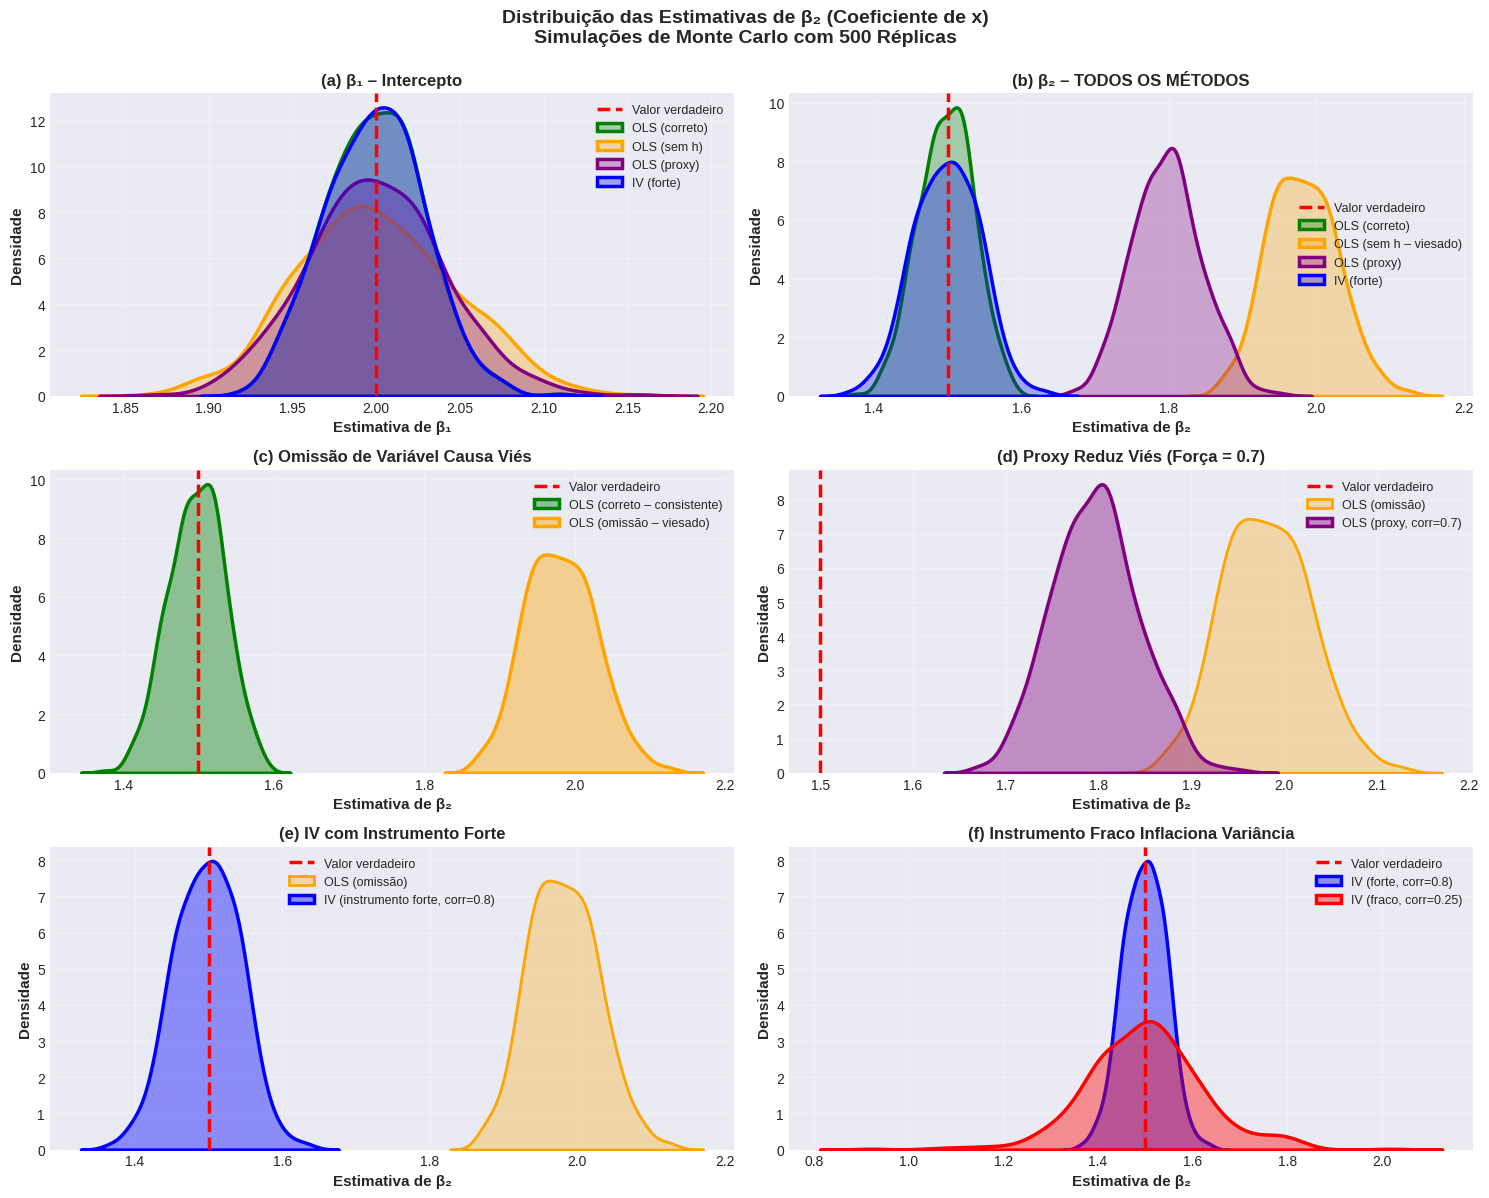

In [11]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle('Distribuição das Estimativas de β₂ (Coeficiente de x)\n'
             'Simulações de Monte Carlo com 500 Réplicas',
             fontsize=14, fontweight='bold', y=0.995)

# Linha 1, Coluna 1: β₁
ax = axes[0, 0]
ax.axvline(b1_true, color='red', linestyle='--', linewidth=2.5, label='Valor verdadeiro', zorder=5)
sns.kdeplot(data=b1_ols_correto, ax=ax, linewidth=2.5, label='OLS (correto)', 
           color='green', fill=True, alpha=0.3)
sns.kdeplot(data=b1_ols_viesado, ax=ax, linewidth=2.5, label='OLS (sem h)', 
           color='orange', fill=True, alpha=0.3)
sns.kdeplot(data=b1_ols_proxy, ax=ax, linewidth=2.5, label='OLS (proxy)', 
           color='purple', fill=True, alpha=0.3)
sns.kdeplot(data=b1_iv_forte, ax=ax, linewidth=2.5, label='IV (forte)', 
           color='blue', fill=True, alpha=0.3)
ax.set_xlabel('Estimativa de β₁', fontsize=11, fontweight='bold')
ax.set_ylabel('Densidade', fontsize=11, fontweight='bold')
ax.set_title('(a) β₁ – Intercepto', fontsize=12, fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

# Linha 1, Coluna 2: β₂ TODOS os métodos
ax = axes[0, 1]
ax.axvline(b2_true, color='red', linestyle='--', linewidth=2.5, label='Valor verdadeiro', zorder=5)
sns.kdeplot(data=b2_ols_correto, ax=ax, linewidth=2.5, label='OLS (correto)', 
           color='green', fill=True, alpha=0.3)
sns.kdeplot(data=b2_ols_viesado, ax=ax, linewidth=2.5, label='OLS (sem h – viesado)', 
           color='orange', fill=True, alpha=0.3)
sns.kdeplot(data=b2_ols_proxy, ax=ax, linewidth=2.5, label='OLS (proxy)', 
           color='purple', fill=True, alpha=0.3)
sns.kdeplot(data=b2_iv_forte, ax=ax, linewidth=2.5, label='IV (forte)', 
           color='blue', fill=True, alpha=0.3)
ax.set_xlabel('Estimativa de β₂', fontsize=11, fontweight='bold')
ax.set_ylabel('Densidade', fontsize=11, fontweight='bold')
ax.set_title('(b) β₂ – TODOS OS MÉTODOS', fontsize=12, fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

# Linha 2, Coluna 1: OLS correto vs omissão
ax = axes[1, 0]
ax.axvline(b2_true, color='red', linestyle='--', linewidth=2.5, label='Valor verdadeiro', zorder=5)
sns.kdeplot(data=b2_ols_correto, ax=ax, linewidth=2.5, label='OLS (correto – consistente)', 
           color='green', fill=True, alpha=0.4)
sns.kdeplot(data=b2_ols_viesado, ax=ax, linewidth=2.5, label='OLS (omissão – viesado)', 
           color='orange', fill=True, alpha=0.4)
ax.set_xlabel('Estimativa de β₂', fontsize=11, fontweight='bold')
ax.set_ylabel('Densidade', fontsize=11, fontweight='bold')
ax.set_title('(c) Omissão de Variável Causa Viés', fontsize=12, fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

# Linha 2, Coluna 2: OLS com proxy
ax = axes[1, 1]
ax.axvline(b2_true, color='red', linestyle='--', linewidth=2.5, label='Valor verdadeiro', zorder=5)
sns.kdeplot(data=b2_ols_viesado, ax=ax, linewidth=2, label='OLS (omissão)', 
           color='orange', fill=True, alpha=0.3)
sns.kdeplot(data=b2_ols_proxy, ax=ax, linewidth=2.5, label=f'OLS (proxy, corr={forca_proxy})', 
           color='purple', fill=True, alpha=0.4)
ax.set_xlabel('Estimativa de β₂', fontsize=11, fontweight='bold')
ax.set_ylabel('Densidade', fontsize=11, fontweight='bold')
ax.set_title(f'(d) Proxy Reduz Viés (Força = {forca_proxy})', fontsize=12, fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

# Linha 3, Coluna 1: IV forte
ax = axes[2, 0]
ax.axvline(b2_true, color='red', linestyle='--', linewidth=2.5, label='Valor verdadeiro', zorder=5)
sns.kdeplot(data=b2_ols_viesado, ax=ax, linewidth=2, label='OLS (omissão)', 
           color='orange', fill=True, alpha=0.3)
sns.kdeplot(data=b2_iv_forte, ax=ax, linewidth=2.5, label=f'IV (instrumento forte, corr={forca_instrumento_forte})', 
           color='blue', fill=True, alpha=0.4)
ax.set_xlabel('Estimativa de β₂', fontsize=11, fontweight='bold')
ax.set_ylabel('Densidade', fontsize=11, fontweight='bold')
ax.set_title(f'(e) IV com Instrumento Forte', fontsize=12, fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

# Linha 3, Coluna 2: IV forte vs fraco
ax = axes[2, 1]
ax.axvline(b2_true, color='red', linestyle='--', linewidth=2.5, label='Valor verdadeiro', zorder=5)
sns.kdeplot(data=b2_iv_forte, ax=ax, linewidth=2.5, label=f'IV (forte, corr={forca_instrumento_forte})', 
           color='blue', fill=True, alpha=0.4)
sns.kdeplot(data=b2_iv_fraco, ax=ax, linewidth=2.5, label=f'IV (fraco, corr={forca_instrumento_fraco})', 
           color='red', fill=True, alpha=0.4)
ax.set_xlabel('Estimativa de β₂', fontsize=11, fontweight='bold')
ax.set_ylabel('Densidade', fontsize=11, fontweight='bold')
ax.set_title('(f) Instrumento Fraco Inflaciona Variância', fontsize=12, fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_01_densidades_b2.png', dpi=150, bbox_inches='tight')
print("✓ Gráfico 1 salvo: fig_01_densidades_b2.png")
plt.show()

## 11. GRÁFICO 2: Densidades de β₃

✓ Gráfico 2 salvo: fig_02_densidades_b3.png


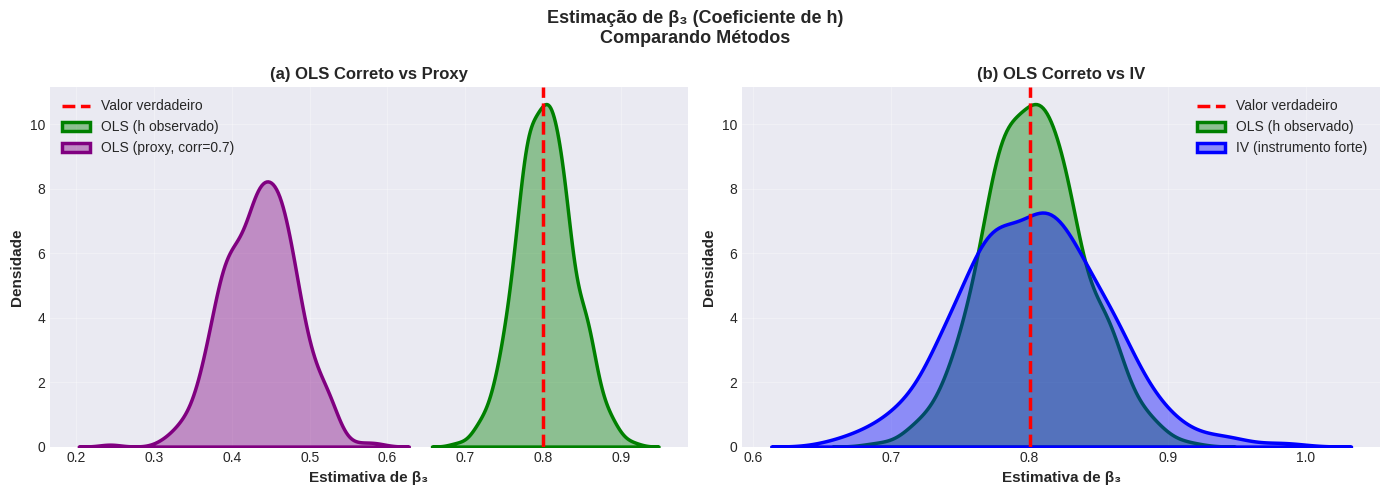

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Estimação de β₃ (Coeficiente de h)\nComparando Métodos',
             fontsize=13, fontweight='bold')

# Coluna 1: OLS correto vs proxy
ax = axes[0]
ax.axvline(b3_true, color='red', linestyle='--', linewidth=2.5, label='Valor verdadeiro', zorder=5)
sns.kdeplot(data=b3_ols_correto, ax=ax, linewidth=2.5, label='OLS (h observado)', 
           color='green', fill=True, alpha=0.4)
sns.kdeplot(data=b3_ols_proxy, ax=ax, linewidth=2.5, 
           label=f'OLS (proxy, corr={forca_proxy})', 
           color='purple', fill=True, alpha=0.4)
ax.set_xlabel('Estimativa de β₃', fontsize=11, fontweight='bold')
ax.set_ylabel('Densidade', fontsize=11, fontweight='bold')
ax.set_title('(a) OLS Correto vs Proxy', fontsize=12, fontweight='bold')
ax.legend(loc='best', fontsize=10)
ax.grid(True, alpha=0.3)

# Coluna 2: OLS correto vs IV
ax = axes[1]
ax.axvline(b3_true, color='red', linestyle='--', linewidth=2.5, label='Valor verdadeiro', zorder=5)
sns.kdeplot(data=b3_ols_correto, ax=ax, linewidth=2.5, label='OLS (h observado)', 
           color='green', fill=True, alpha=0.4)
sns.kdeplot(data=b3_iv_forte, ax=ax, linewidth=2.5, label=f'IV (instrumento forte)', 
           color='blue', fill=True, alpha=0.4)
ax.set_xlabel('Estimativa de β₃', fontsize=11, fontweight='bold')
ax.set_ylabel('Densidade', fontsize=11, fontweight='bold')
ax.set_title('(b) OLS Correto vs IV', fontsize=12, fontweight='bold')
ax.legend(loc='best', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_02_densidades_b3.png', dpi=150, bbox_inches='tight')
print("✓ Gráfico 2 salvo: fig_02_densidades_b3.png")
plt.show()

## 12. GRÁFICO 3: Bias-Variance Tradeoff

✓ Gráfico 3 salvo: fig_03_bias_variance.png


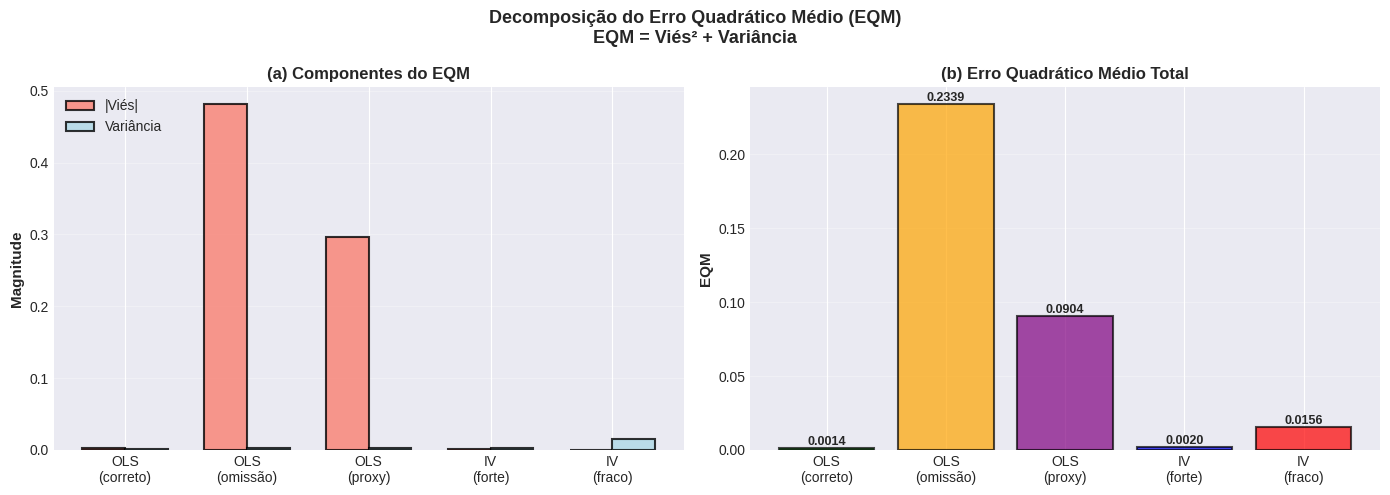

In [13]:
# Preparar dados
metodos = ['OLS\n(correto)', 'OLS\n(omissão)', 'OLS\n(proxy)', 'IV\n(forte)', 'IV\n(fraco)']
estimativas = [b2_ols_correto, b2_ols_viesado, b2_ols_proxy, b2_iv_forte, b2_iv_fraco]
cores = ['green', 'orange', 'purple', 'blue', 'red']

vieses = [est.mean() - b2_true for est in estimativas]
variancias = [est.var() for est in estimativas]
erros_quadraticos = [(est - b2_true).var() + (est.mean() - b2_true)**2 for est in estimativas]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Decomposição do Erro Quadrático Médio (EQM)\nEQM = Viés² + Variância',
             fontsize=13, fontweight='bold')

# Coluna 1: Viés vs Variância
ax = axes[0]
x_pos = np.arange(len(metodos))
width = 0.35
bars1 = ax.bar(x_pos - width/2, np.abs(vieses), width, label='|Viés|', 
               alpha=0.8, color='salmon', edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x_pos + width/2, variancias, width, label='Variância', 
               alpha=0.8, color='lightblue', edgecolor='black', linewidth=1.5)

ax.set_ylabel('Magnitude', fontsize=11, fontweight='bold')
ax.set_title('(a) Componentes do EQM', fontsize=12, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(metodos, fontsize=10)
ax.legend(fontsize=10, loc='upper left')
ax.grid(True, alpha=0.3, axis='y')

# Coluna 2: EQM Total
ax = axes[1]
bars = ax.bar(range(len(metodos)), erros_quadraticos, color=cores, alpha=0.7, 
              edgecolor='black', linewidth=1.5)
ax.set_ylabel('EQM', fontsize=11, fontweight='bold')
ax.set_title('(b) Erro Quadrático Médio Total', fontsize=12, fontweight='bold')
ax.set_xticks(range(len(metodos)))
ax.set_xticklabels(metodos, fontsize=10)
ax.grid(True, alpha=0.3, axis='y')

for i, (bar, val) in enumerate(zip(bars, erros_quadraticos)):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height(),
           f'{val:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('fig_03_bias_variance.png', dpi=150, bbox_inches='tight')
print("✓ Gráfico 3 salvo: fig_03_bias_variance.png")
plt.show()

## 13. TABELA RESUMO E CONCLUSÃO

In [14]:
print("\n" + "="*100)
print("RESUMO FINAL: Quando Usar Cada Método")
print("="*100)

print(f"""
✓ OLS COM ESPECIFICAÇÃO CORRETA
  • Viés: {b2_ols_correto.mean() - b2_true:+.6f} (praticamente zero)
  • Variância: {b2_ols_correto.var():.6f}
  • Conclusão: Consistente e eficiente ✓

✗ OLS COM OMISSÃO DE VARIÁVEL  
  • Viés: {b2_ols_viesado.mean() - b2_true:+.6f} (SIGNIFICATIVO!)
  • Variância: {b2_ols_viesado.var():.6f}
  • Conclusão: Viesado e inconsistente ✗

~ OLS COM PROXY
  • Viés: {b2_ols_proxy.mean() - b2_true:+.6f} (reduzido vs omissão)
  • Variância: {b2_ols_proxy.var():.6f}
  • Redução de viés: {(b2_ols_viesado.mean() - b2_true) - (b2_ols_proxy.mean() - b2_true):.6f}
  • Conclusão: Melhora com proxy forte ✓

✓ IV COM INSTRUMENTO FORTE (F > 10)
  • Viés: {b2_iv_forte.mean() - b2_true:+.6f} (quase zero)
  • Variância: {b2_iv_forte.var():.6f} (maior que OLS, mas aceitável)
  • Conclusão: Consistente mesmo com endogeneidade ✓

⚠️  IV COM INSTRUMENTO FRACO (F < 10)
  • Viés: {b2_iv_fraco.mean() - b2_true:+.6f}
  • Variância: {b2_iv_fraco.var():.6f} (DRAMATICAMENTE INFLADA!)
  • Razão: {b2_iv_fraco.std() / b2_iv_forte.std():.2f}x maior que instrumento forte
  • Conclusão: Evitar a todo custo ✗

─────────────────────────────────────────────────────────────────────────────────────────

REGRA DE OURO PARA INSTRUMENTOS:
  • F-statistic do 1º estágio > 10 → Instrumento é forte ✓
  • F-statistic do 1º estágio < 10 → Instrumento é fraco (cuidado!) ⚠️
  • F-statistic do 1º estágio < 5  → Instrumento não serve ✗

ESTRATÉGIA RECOMENDADA:
  1. Se possível, use OLS com todas as variáveis relevantes
  2. Se não conseguir observar tudo: use proxy (se houver)
  3. IV é a última opção, mas requer instrumento FORTE!
""")


RESUMO FINAL: Quando Usar Cada Método

✓ OLS COM ESPECIFICAÇÃO CORRETA
  • Viés: -0.002481 (praticamente zero)
  • Variância: 0.001374
  • Conclusão: Consistente e eficiente ✓

✗ OLS COM OMISSÃO DE VARIÁVEL  
  • Viés: +0.481290 (SIGNIFICATIVO!)
  • Variância: 0.002222
  • Conclusão: Viesado e inconsistente ✗

~ OLS COM PROXY
  • Viés: +0.297064 (reduzido vs omissão)
  • Variância: 0.002152
  • Redução de viés: 0.184226
  • Conclusão: Melhora com proxy forte ✓

✓ IV COM INSTRUMENTO FORTE (F > 10)
  • Viés: -0.001854 (quase zero)
  • Variância: 0.002021 (maior que OLS, mas aceitável)
  • Conclusão: Consistente mesmo com endogeneidade ✓

⚠️  IV COM INSTRUMENTO FRACO (F < 10)
  • Viés: -0.000520
  • Variância: 0.015615 (DRAMATICAMENTE INFLADA!)
  • Razão: 2.78x maior que instrumento forte
  • Conclusão: Evitar a todo custo ✗

─────────────────────────────────────────────────────────────────────────────────────────

REGRA DE OURO PARA INSTRUMENTOS:
  • F-statistic do 1º estágio > 10 → Ins